In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('players_data-2025_2026.csv')
print(df.columns.tolist())

['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'G+A-PK', 'Rk_stats_keeper', 'Nation_stats_keeper', 'Pos_stats_keeper', 'Comp_stats_keeper', 'Age_stats_keeper', 'Born_stats_keeper', 'MP_stats_keeper', 'Starts_stats_keeper', 'Min_stats_keeper', '90s_stats_keeper', 'GA', 'GA90', 'SoTA', 'Saves', 'Save%', 'W', 'D', 'L', 'CS', 'CS%', 'PKatt_stats_keeper', 'PKA', 'PKsv', 'PKm', 'Rk_stats_shooting', 'Nation_stats_shooting', 'Pos_stats_shooting', 'Comp_stats_shooting', 'Age_stats_shooting', 'Born_stats_shooting', '90s_stats_shooting', 'Gls_stats_shooting', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'PK_stats_shooting', 'PKatt_stats_shooting', 'Rk_stats_playing_time', 'Nation_stats_playing_time', 'Pos_stats_playing_time', 'Comp_stats_playing_time', 'Age_stats_playing_time', 'Born_stats_playing_time', 'MP_stats_playing_time', 'Min_stats_playing_time', 'Mn/MP', 'Min%', '90s_s

Fase 1: Construyendo el Multiverso del Jugador (Min. 4 Dimensiones)


In [17]:
metrics = ['Min', 'Gls', 'Ast', 'Sh/90', 'SoT/90']
nombre_star = "Jude Bellingham"

new_df = df[['Player'] + metrics].dropna().astype({m: float for m in metrics})
new_df = new_df[new_df['Min'] >= 450]  

star = new_df[new_df['Player'] == nombre_star]
players = new_df[new_df['Player'] != nombre_star]

print(star)
print(players.shape)

              Player     Min  Gls  Ast  Sh/90  SoT/90
270  Jude Bellingham  1916.0  6.0  4.0    2.4    1.22
(1998, 6)


In [18]:
star_vec = star[metrics]
players_vec = players[metrics]

Pregunta de control: Antes de medir cualquier distancia, ¿qué operación de la Unidad II deben aplicarle obligatoriamente a estas 4 columnas para que los Minutos_Jugados (rango en miles) no aplasten matemáticamente a los Goles (rango en decenas)? Apliquen esa transformación en el código.


In [19]:
players_scaled = (players_vec - players_vec.mean()) / players_vec.std()
star_scaled = (star_vec - players_vec.mean()) / players_vec.std()


--> Hay que aplicar normalización (estandarización z-score), porque Min está en miles y Gls en decenas. Sin escalar, los minutos dominarían la distancia.

Fase 2: El Duelo de Distancias (Euclidiana vs. Manhattan)

Distancia Euclidiana

In [20]:
players = players.copy()
players['euclidiana'] = np.linalg.norm(players_scaled.values - star_scaled.values, axis=1)

idx_eu = players['euclidiana'].idxmin()
print("Reemplazo (Euclidiana):", players.loc[idx_eu, 'Player'])
print("Distancia:", round(players.loc[idx_eu, 'euclidiana'], 3))

Reemplazo (Euclidiana): Ragnar Ache
Distancia: 0.548


Distancia Manhattan

In [21]:
def distancia_manhattan(a, b):
    return np.sum(np.abs(a - b), axis=1)

players['manhattan'] = distancia_manhattan(players_scaled.values, star_scaled.values)

idx_mh = players['manhattan'].idxmin()
print("Reemplazo (Manhattan):", players.loc[idx_mh, 'Player'])
print("Distancia:", round(players.loc[idx_mh, 'manhattan'], 3))
print("Mismo jugador:", idx_eu == idx_mh)

Reemplazo (Manhattan): Julián Álvarez
Distancia: 0.829
Mismo jugador: False


Análisis Crítico: ¿El algoritmo sugirió al mismo jugador en ambos casos? Como ingenieros, expliquen en un bloque de Markdown las diferencias observables entre la Distancia Euclidiana comparado con la Distancia Manhattan.

--> 

Top 5 en c/metrica

In [22]:
print(players.nsmallest(5, 'euclidiana')[['Player', 'euclidiana']])
print(players.nsmallest(5, 'manhattan')[['Player', 'manhattan']])

              Player  euclidiana
20       Ragnar Ache    0.547787
94    Julián Álvarez    0.632442
2040     Igor Paixão    0.688105
371    Julian Brandt    0.773613
399    Marius Bülter    0.819118
                     Player  manhattan
94           Julián Álvarez   0.828979
20              Ragnar Ache   1.066765
2040            Igor Paixão   1.203209
399           Marius Bülter   1.383343
551   Alexis Claude-Maurice   1.468928


Fase 3: El Reto de Visualización en 4D (Investigación Independiente)

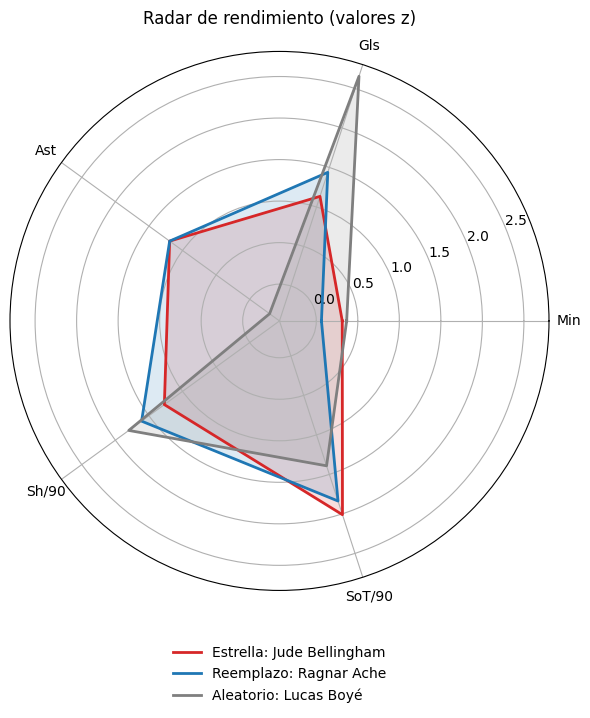

In [23]:
idx_random = players.drop(index=idx_eu).sample(1, random_state=42).index[0]

nombres = [nombre_star, players.loc[idx_eu, 'Player'], players.loc[idx_random, 'Player']]
vectores = [star_scaled.values[0],
            players_scaled.loc[idx_eu].values,
            players_scaled.loc[idx_random].values]
etiquetas = [f'Estrella: {nombres[0]}', f'Reemplazo: {nombres[1]}', f'Aleatorio: {nombres[2]}']
colores = ['#d62728', '#1f77b4', '#7f7f7f']

angulos = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

for vec, etiqueta, color in zip(vectores, etiquetas, colores):
    valores = list(vec) + [vec[0]]
    ax.plot(angulos, valores, color=color, linewidth=2, label=etiqueta)
    ax.fill(angulos, valores, color=color, alpha=0.15)

ax.set_xticks(angulos[:-1])
ax.set_xticklabels(metrics)
ax.set_title('Radar de rendimiento (valores z)', pad=20)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.show()

Analisis de la grafica/conclusion
--> El polígono del reemplazo se superpone casi por completo con el de la estrella, mientras que el del jugador aleatorio tiene una forma distinta. Esto coincide con las distancias: el reemplazo está mucho más cerca que el aleatorio en el espacio estandarizado.